# Laboratorio 3 — La tarea de clasificación

**Curso:** ISIS2611
**Integrantes:** David Lucuara-202410218, Jose Pardo

> **Propósito:** construir y comparar modelos de clasificación (regresión logística, árboles de decisión y Random Forest) que anticipen cuándo un conductor de Ruta Alpes aceptará un cupón de **Cafetería** o de **Restaurante(<20)**, evaluar si una técnica de balanceo de clases mejora el modelo de Restaurante(<20), identificar los factores del contexto de conducción y del perfil del conductor que más influyen en la aceptación, y analizar los riesgos de sesgo de personalizar ofertas con variables demográficas

## Tabla de contenido

1. Contexto del caso
2. Configuración del entorno
3. Carga de datos
4. Exploración de los datos (actividad 1)
5. Limpieza y preparación de los datos (actividad 2)
6. Modelo 1 — Regresión logística (actividad 3)
7. Modelo 2 — Árbol de decisión (actividad 4)
8. Modelo 3 — Random Forest (actividad 5)
9. Balanceo de clases en Restaurante(<20) (actividad 6)
10. Comparación en test y selección del mejor modelo (actividad 7)
11. Variables más relevantes (actividad 8)
12. Predicciones sobre los datos de prueba (actividad 10)
13. Análisis de resultados
14. Conclusiones
15. Guion del video (actividad 9)
16. Uso de herramientas de IA generativa

# 1. Contexto del caso

Ruta Alpes es una aplicación de asistencia de conducción que, además de navegación, recomienda cupones de establecimientos cercanos a la ruta del conductor (restaurantes, cafeterías, bares y comida para llevar). Enviar la misma oferta a todos los usuarios ha mostrado baja efectividad y genera notificaciones irrelevantes en momentos inoportunos, por lo que la empresa quiere identificar, **para un tipo de cupón determinado, cuándo un conductor tiene mayor probabilidad de aceptarlo**, y así personalizar su estrategia de ofertas.

Como primera aproximación se trabaja con dos tipos de cupón: **Cafetería** y **Restaurante(<20)**. Se construye un modelo independiente para cada uno, ya que los factores que llevan a aceptar un café no tienen por qué ser los mismos que llevan a aceptar una comida, y la distribución de clases puede diferir entre ambos subconjuntos.

- **Variable objetivo:** `acepta_cupon` (`Sí` / `No`). Se codifica `Sí` = 1 (clase positiva, el evento de interés para el negocio) y `No` = 0.
- **Unidad de análisis:** un escenario de conducción en el que se ofrece un cupón a un conductor, descrito por variables del contexto (destino, hora, clima, acompañante, distancia y vigencia del cupón) y del perfil del conductor (variables demográficas y hábitos de consumo).
- **Métrica principal:** se usa el **F1-score macro** para seleccionar los modelos. El F1 equilibra precisión (no mostrar cupones que serán rechazados, lo que genera molestia) y recall (no perder conductores que sí lo aceptarían), y su versión macro promedia el F1 de ambas clases con el mismo peso, de modo que la clase mayoritaria no infle el resultado. Esto es relevante si alguno de los subconjuntos presenta desbalance (ver sección 4.7). Como complemento se reportan precisión, recall y F1 de la clase `Sí` y el recall de la clase minoritaria.

# 2. Configuración del entorno


In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    make_scorer, confusion_matrix, ConfusionMatrixDisplay,
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

In [3]:

RANDOM_STATE = 42
TEST_SIZE = 0.25
N_SPLITS_CV = 5

TARGET = "acepta_cupon"
CLASE_POSITIVA = "Sí"                     
CUPONES = ["Cafetería", "Restaurante(<20)"]
METRICA_REFIT = "f1_macro" 

# 3. Carga de datos



In [4]:
# datos etiquetados

data_original = pd.read_excel("./data/Lab3_Datos.xlsx")
data = data_original.copy()

print("Dimensiones originales:", data.shape)
data.head()

Dimensiones originales: (12664, 26)


,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,tiene_hijos,educacion,ocupacion,ingreso,vehiculo,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No
2,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Comida para llevar,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No


In [5]:
# diccionario de datos
diccionario_datos = pd.read_excel("./data/Lab3_diccionario_Datos.xlsx")
with pd.option_context("display.max_colwidth", 200):
    display(diccionario_datos)

,Variable,Tipo,Descripción
0,destino,Categórica nominal,"Destino del trayecto en el momento en que se ofrece el cupón. Valores posibles: Casa, Sin lugar urgente, Trabajo."
1,acompanante,Categórica nominal,"Tipo de acompañante(s) en el vehículo al momento de la oferta. Valores posibles: Solo, Amigo(s), Hijo(s), Pareja."
2,clima,Categórica nominal,"Condición climática durante el trayecto. Valores posibles: Soleado, Lluvioso, Nevado."
3,temperatura,Numérica entero,"Temperatura ambiente en grados Fahrenheit. Variable de diseño de la encuesta: solo toma 3 valores fijos, asociados al clima. Rango: {30, 55, 80}."
4,hora,Categórica ordinal,"Hora del día en que ocurre el trayecto. Valores posibles (en orden): 7:00 a.m., 10:00 a.m., 2:00 p.m., 6:00 p.m., 10:00 p.m."
5,cupon,Categórica nominal,"Tipo de cupón ofrecido al conductor. Valores posibles: Bar, Cafetería, Comida para llevar, Restaurante(<20), Restaurante(20-50). Los valores <20 y 20-50 indican los gastos pormedios por persona pa..."
6,vigencia_cupon,Categórica nominal,"Tiempo de vigencia del cupón antes de expirar. Valores posibles: 2 horas, 1 día."
7,genero,Categórica nominal,"Género reportado por el conductor. Valores posibles: Femenino, Masculino."
8,edad,Categórica ordinal,"Rango de edad del conductor. Valores posibles (en orden): menor de 21, 21, 26, 31, 36, 41, 46, 50 o más."
9,estado_civil,Categórica nominal,"Estado civil del conductor. Valores posibles: Soltero(a), Casado(a), Unión libre, Divorciado(a), Viudo(a)."


In [6]:
# datos de prueba sin etiqueta

datos_prueba_original = pd.read_excel("./data/Lab3_datos_Prueba.xlsx")

print("Dimensiones datos de prueba:", datos_prueba_original.shape)
datos_prueba_original.head()

Dimensiones datos de prueba: (20, 25)


,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,tiene_hijos,educacion,ocupacion,ingreso,vehiculo,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta
0,Trabajo,Solo,Soleado,55,7:00 a.m.,Cafetería,2 horas,Femenino,50 o más,Divorciado(a),Sí,Posgrado (Maestría o Doctorado),Jubilado(a),$12.500 - $24.999,NaN,1 a 3,4 a 8,4 a 8,4 a 8,menos de 1,Sí,Sí,No,No,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,31,Unión libre,No,Estudios universitarios sin título,Apoyo Administrativo y de Oficina,$75.000 - $87.499,NaN,menos de 1,1 a 3,más de 8,4 a 8,1 a 3,Sí,No,No,No,Sí
2,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,31,Soltero(a),No,Pregrado,Transporte y Manejo de Materiales,$25.000 - $37.499,NaN,menos de 1,1 a 3,4 a 8,más de 8,menos de 1,Sí,Sí,No,No,Sí
3,Sin lugar urgente,Pareja,Soleado,80,10:00 a.m.,Cafetería,2 horas,Masculino,50 o más,Casado(a),Sí,Estudios universitarios sin título,Computación y Matemáticas,$50.000 - $62.499,NaN,nunca,más de 8,nunca,4 a 8,menos de 1,Sí,No,No,No,Sí
4,Sin lugar urgente,Amigo(s),Soleado,80,6:00 p.m.,Restaurante(<20),2 horas,Femenino,26,Soltero(a),No,Técnico/Tecnólogo,Desempleado(a),Menos de $12.500,NaN,1 a 3,menos de 1,4 a 8,menos de 1,4 a 8,Sí,Sí,No,No,Sí


# 4. Exploración de los datos

**Actividad 1 (5%).** Exploración de los datos para identificar problemas de calidad y otras características relevantes de cada subconjunto (Cafetería y Restaurante(<20)), incluyendo la distribución de `acepta_cupon` en cada uno.

## 4.1 Estructura general y tipos de datos

In [7]:
data.info()
data.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 12664 entries, 0 to 12663
Data columns (total 26 columns):
 #   Column                           Non-Null Count  Dtype
---  ------                           --------------  -----
 0   destino                          12664 non-null  str  
 1   acompanante                      12664 non-null  str  
 2   clima                            12664 non-null  str  
 3   temperatura                      12664 non-null  int64
 4   hora                             12664 non-null  str  
 5   cupon                            12664 non-null  str  
 6   vigencia_cupon                   12664 non-null  str  
 7   genero                           12664 non-null  str  
 8   edad                             12664 non-null  str  
 9   estado_civil                     12664 non-null  str  
 10  tiene_hijos                      12664 non-null  str  
 11  educacion                        12664 non-null  str  
 12  ocupacion                        12664 non-null  str  
 1

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
destino,12664,3,Sin lugar urgente,6270,NaN,NaN,NaN,NaN,NaN,NaN,NaN
acompanante,12664,4,Solo,7296,NaN,NaN,NaN,NaN,NaN,NaN,NaN
clima,12664,3,Soleado,10052,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temperatura,12664.0,NaN,NaN,NaN,63.287271,19.15813,30.0,55.0,80.0,80.0,80.0
hora,12664,5,6:00 p.m.,3224,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cupon,12664,5,Cafetería,3986,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vigencia_cupon,12664,2,1 día,7081,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genero,12664,2,Femenino,6501,NaN,NaN,NaN,NaN,NaN,NaN,NaN
edad,12664,8,21,2652,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estado_civil,12664,5,Casado(a),5092,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4.2 Valores ausentes

In [8]:
tabla_ausentes = pd.DataFrame({
    "ausentes": data.isna().sum(),
    "porcentaje": 100 * data.isna().mean(),
}).query("ausentes > 0").sort_values("porcentaje", ascending=False)
display(tabla_ausentes.round(2))

# porcentaje de ausentes dentro de cada subconjunto de interés
pd.DataFrame({
    cupon: 100 * data.loc[data["cupon"] == cupon].isna().mean()
    for cupon in CUPONES
}).loc[tabla_ausentes.index].round(2)

,ausentes,porcentaje
vehiculo,12556,99.15
frecuencia_cafeteria,217,1.71
frecuencia_restaurante_20_a_50,189,1.49
frecuencia_comida_para_llevar,151,1.19
frecuencia_restaurante_menos_20,130,1.03
frecuencia_bar,107,0.84


,Cafetería,Restaurante(<20)
vehiculo,99.07,99.10
frecuencia_cafeteria,1.81,1.69
frecuencia_restaurante_20_a_50,1.38,1.55
frecuencia_comida_para_llevar,1.43,1.22
frecuencia_restaurante_menos_20,1.25,0.97
frecuencia_bar,0.93,0.83


## 4.3 Registros duplicados

In [9]:
columnas_predictoras = [c for c in data.columns if c != TARGET]

print("Duplicados exactos (todo el conjunto):", data.duplicated().sum())
for cupon in CUPONES:
    sub = data[data["cupon"] == cupon]
    grupos = (
        sub[sub.duplicated(subset=columnas_predictoras, keep=False)]
        .groupby(columnas_predictoras, dropna=False)[TARGET].nunique()
    )
    print(f"{cupon}: {sub.duplicated().sum()} duplicados exactos | "
          f"{(grupos > 1).sum()} escenarios idénticos con etiqueta contradictoria")




variables_perfil = [
    "genero", "edad", "estado_civil", "tiene_hijos", "educacion", "ocupacion", "ingreso",
    "frecuencia_bar", "frecuencia_cafeteria", "frecuencia_comida_para_llevar",
    "frecuencia_restaurante_menos_20", "frecuencia_restaurante_20_a_50",
]
for cupon in CUPONES:
    sub = data[data["cupon"] == cupon]
    perfiles = sub[variables_perfil].drop_duplicates().shape[0]
    print(f"{cupon}: {len(sub)} registros, {perfiles} perfiles de conductor distintos "
          f"(~{len(sub) / perfiles:.1f} escenarios por perfil)")

Duplicados exactos (todo el conjunto): 74
Cafetería: 7 duplicados exactos | 4 escenarios idénticos con etiqueta contradictoria
Restaurante(<20): 7 duplicados exactos | 3 escenarios idénticos con etiqueta contradictoria
Cafetería: 3986 registros, 565 perfiles de conductor distintos (~7.1 escenarios por perfil)
Restaurante(<20): 2776 registros, 567 perfiles de conductor distintos (~4.9 escenarios por perfil)


## 4.4 Cardinalidad y variables constantes

In [10]:
tabla_cardinalidad = pd.DataFrame({
    "tipo": data.dtypes.astype(str),
    "valores_unicos": data.nunique(dropna=True),
    "valor_mas_frecuente": data.mode(dropna=True).iloc[0],
    "porcentaje_mas_frecuente": data.apply(lambda s: 100 * s.value_counts(normalize=True).iloc[0]),
}).sort_values("valores_unicos")
display(tabla_cardinalidad.round(2))

print("Columnas constantes:", tabla_cardinalidad.index[tabla_cardinalidad["valores_unicos"] <= 1].tolist())

,tipo,valores_unicos,valor_mas_frecuente,porcentaje_mas_frecuente
tiempo_cupon_mayor_5min,str,1,Sí,100.00
vigencia_cupon,str,2,1 día,55.91
tiene_hijos,str,2,No,58.60
genero,str,2,Femenino,51.33
tiempo_cupon_mayor_25min,str,2,No,88.07
tiempo_cupon_mayor_15min,str,2,Sí,56.17
misma_direccion,str,2,No,78.52
acepta_cupon,str,2,Sí,56.82
direccion_opuesta,str,2,Sí,78.52
clima,str,3,Soleado,79.37


Columnas constantes: ['tiempo_cupon_mayor_5min']


## 4.5 Consistencia con el diccionario de datos

*(Verificar que los valores observados coincidan con los definidos en el diccionario, tanto en los datos etiquetados como en el archivo de prueba.)*

In [11]:
ORDEN_FRECUENCIA = ["nunca", "menos de 1", "1 a 3", "4 a 8", "más de 8"]

ORDEN_CATEGORIAS = {
    "hora": ["7:00 a.m.", "10:00 a.m.", "2:00 p.m.", "6:00 p.m.", "10:00 p.m."],
    "edad": ["menor de 21", "21", "26", "31", "36", "41", "46", "50 o más"],
    "educacion": [
        "Bachillerato incompleto", "Bachillerato completo", "Estudios universitarios sin título",
        "Técnico/Tecnólogo", "Pregrado", "Posgrado (Maestría o Doctorado)",
    ],
    "ingreso": [
        "Menos de $12.500", "$12.500 - $24.999", "$25.000 - $37.499", "$37.500 - $49.999",
        "$50.000 - $62.499", "$62.500 - $74.999", "$75.000 - $87.499", "$87.500 - $99.999",
        "$100.000 o más",
    ],
    "frecuencia_bar": ORDEN_FRECUENCIA,
    "frecuencia_cafeteria": ORDEN_FRECUENCIA,
    "frecuencia_comida_para_llevar": ORDEN_FRECUENCIA,
    "frecuencia_restaurante_menos_20": ORDEN_FRECUENCIA,
    "frecuencia_restaurante_20_a_50": ORDEN_FRECUENCIA,
}

for nombre, df in [("Lab3_Datos", data), ("Lab3_datos_Prueba", datos_prueba_original)]:
    for columna, esperados in ORDEN_CATEGORIAS.items():
        inesperados = set(df[columna].dropna()) - set(esperados)
        if inesperados:
            print(f"{nombre} | {columna}: valores fuera del diccionario -> {inesperados}")
    print(f"{nombre}: revisión de categorías terminada")

columnas_texto = [c for c in data.columns if not pd.api.types.is_numeric_dtype(data[c])]
print("Columnas con espacios al inicio/fin:", [
    c for c in columnas_texto
    if (data[c].dropna() != data[c].dropna().str.strip()).any()
])

Lab3_Datos: revisión de categorías terminada
Lab3_datos_Prueba: revisión de categorías terminada
Columnas con espacios al inicio/fin: []


## 4.6 Variables redundantes o relacionadas entre sí

In [12]:
display(pd.crosstab(data["misma_direccion"], data["direccion_opuesta"]))
display(pd.crosstab(data["clima"], data["temperatura"]))
display(pd.crosstab(data["tiempo_cupon_mayor_15min"], data["tiempo_cupon_mayor_25min"]))
display(pd.crosstab(data["destino"], data["misma_direccion"]))
display(pd.crosstab(data["destino"], data["hora"]))
display(pd.crosstab(data["destino"], data["acompanante"]))

direccion_opuesta,No,Sí
misma_direccion,,
No,0,9944
Sí,2720,0


temperatura,30,55,80
clima,,,
Lluvioso,0,1208,0
Nevado,1404,0,0
Soleado,911,2628,6513


tiempo_cupon_mayor_25min,No,Sí
tiempo_cupon_mayor_15min,,
No,5551,0
Sí,5602,1511


misma_direccion,No,Sí
destino,,
Casa,1712,1521
Sin lugar urgente,6270,0
Trabajo,1962,1199


hora,10:00 a.m.,10:00 p.m.,2:00 p.m.,6:00 p.m.,7:00 a.m.
destino,,,,,
Casa,0,1113,0,2120,0
Sin lugar urgente,2271,890,2005,1104,0
Trabajo,0,0,0,0,3161


acompanante,Amigo(s),Hijo(s),Pareja,Solo
destino,,,,
Casa,0,136,258,2839
Sin lugar urgente,3291,869,814,1296
Trabajo,0,0,0,3161


## 4.7 Subconjuntos Cafetería y Restaurante(<20): distribución de `acepta_cupon`

,cupon,registros,acepta_Si_%,acepta_No_%
0,Cafetería,3986,49.90,50.10
1,Restaurante(<20),2776,70.68,29.32


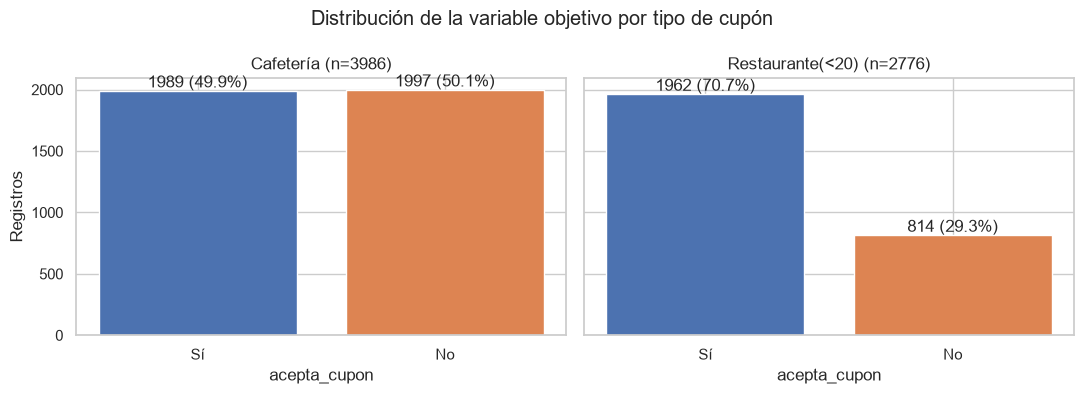

In [13]:
tabla_distribucion = pd.DataFrame([
    {
        "cupon": cupon,
        "registros": (data["cupon"] == cupon).sum(),
        "acepta_Si_%": 100 * (data.loc[data["cupon"] == cupon, TARGET] == "Sí").mean(),
        "acepta_No_%": 100 * (data.loc[data["cupon"] == cupon, TARGET] == "No").mean(),
    }
    for cupon in CUPONES
])
display(tabla_distribucion.round(2))

fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for eje, cupon in zip(ejes, CUPONES):
    conteo = data.loc[data["cupon"] == cupon, TARGET].value_counts().reindex(["Sí", "No"])
    eje.bar(conteo.index, conteo.values, color=["#4C72B0", "#DD8452"])
    for i, v in enumerate(conteo.values):
        eje.text(i, v, f"{v} ({100 * v / conteo.sum():.1f}%)", ha="center", va="bottom")
    eje.set_title(f"{cupon} (n={conteo.sum()})")
    eje.set_xlabel("acepta_cupon")
ejes[0].set_ylabel("Registros")
plt.suptitle("Distribución de la variable objetivo por tipo de cupón")
plt.tight_layout()
plt.show()

## 4.8 Relación de las variables con la aceptación en cada subconjunto

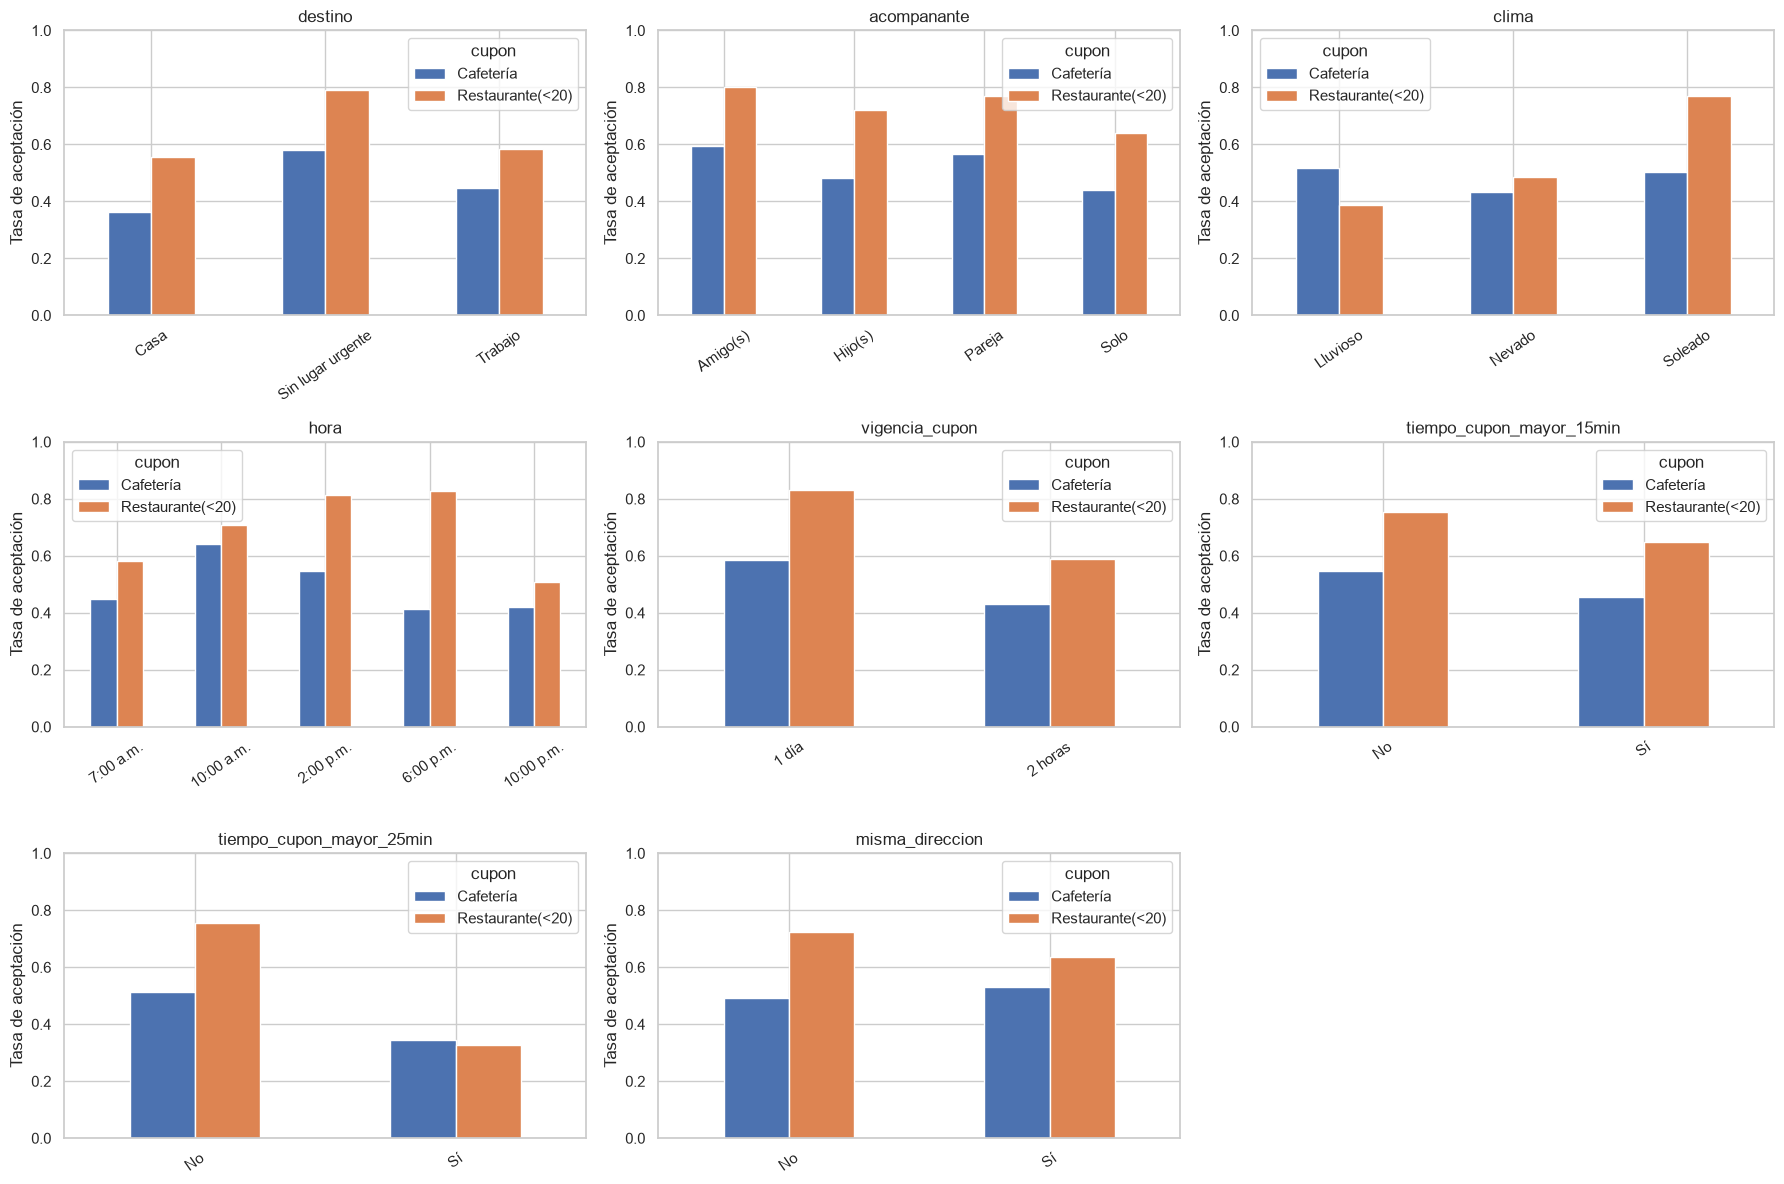

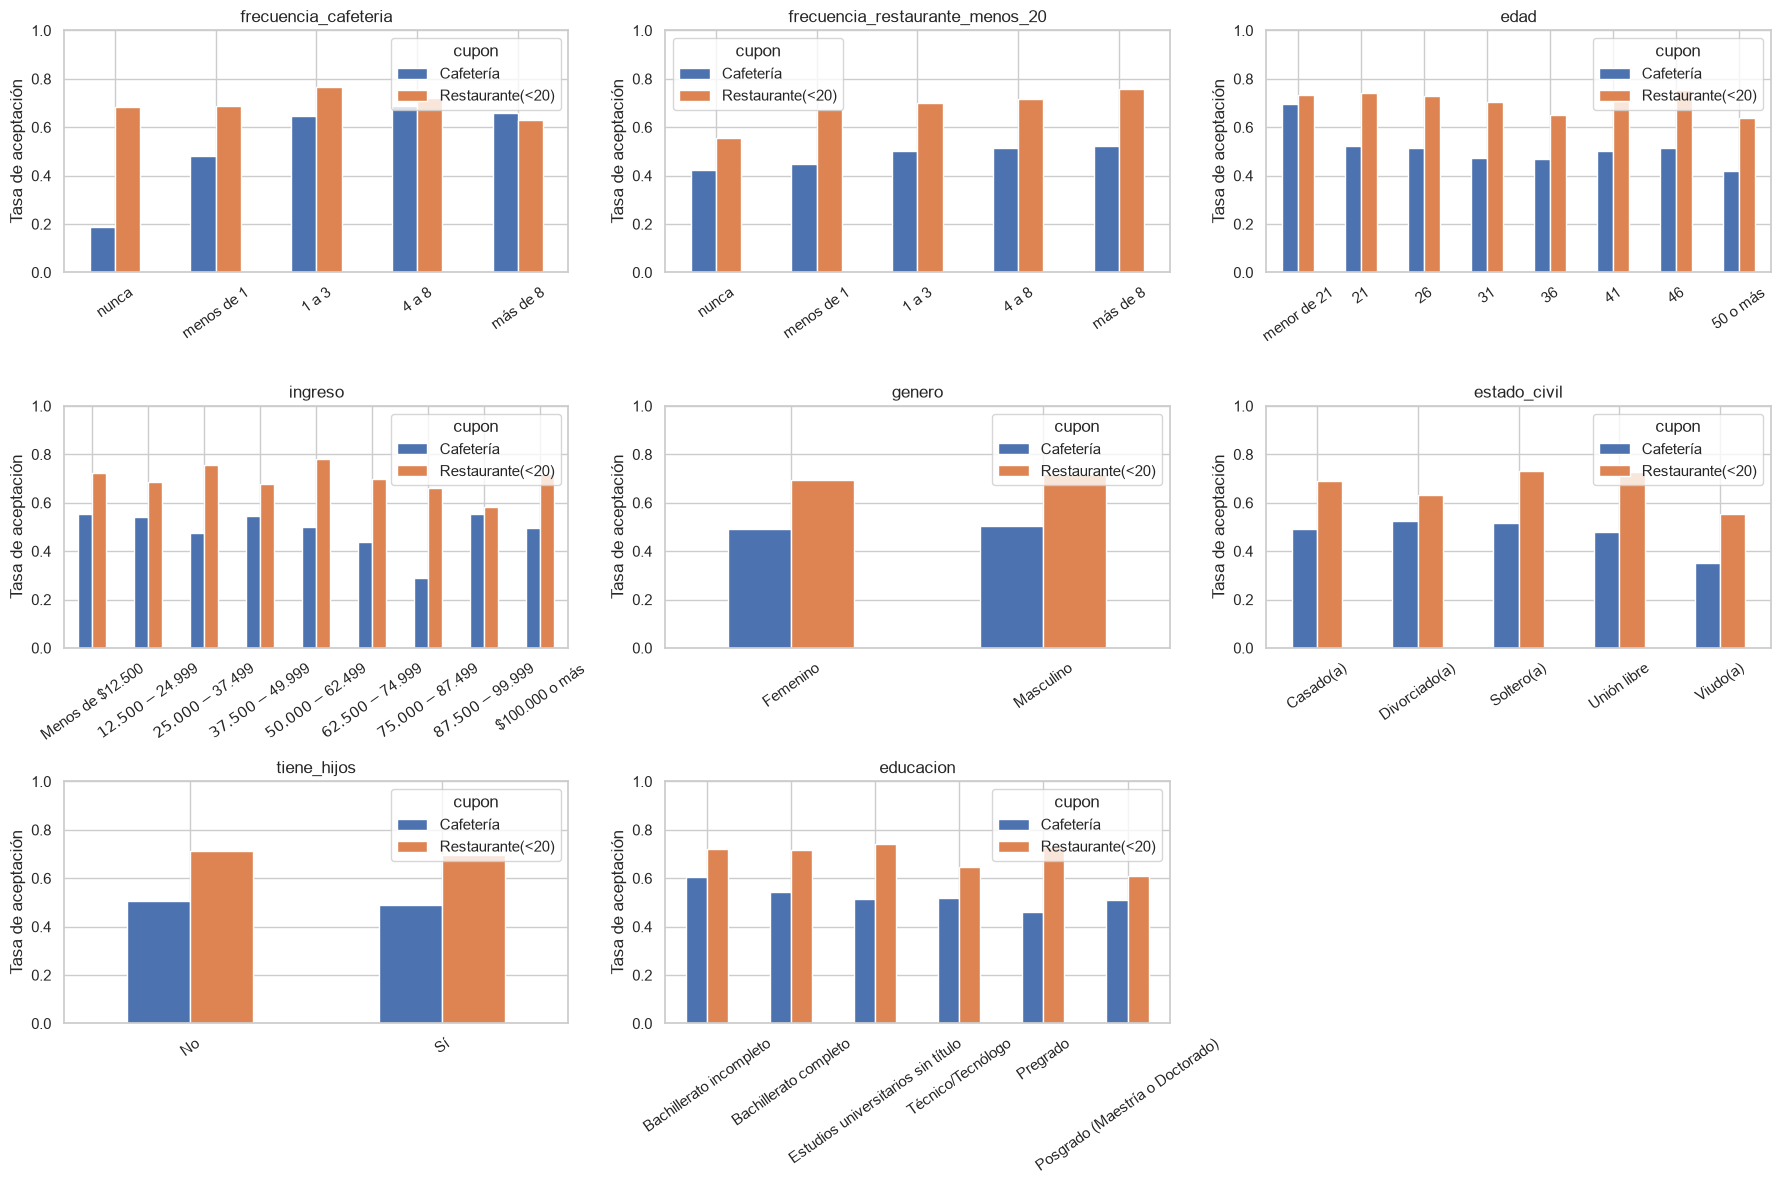

In [14]:
datos_interes = (
    data[data["cupon"].isin(CUPONES)]
    .assign(acepta=lambda d: (d[TARGET] == "Sí").astype(int))
)

def graficar_tasa_aceptacion(variables, ncols=3):
    nfilas = int(np.ceil(len(variables) / ncols))
    fig, ejes = plt.subplots(nfilas, ncols, figsize=(6 * ncols, 4 * nfilas))
    ejes = np.atleast_1d(ejes).ravel()
    for eje, variable in zip(ejes, variables):
        tasas = datos_interes.groupby([variable, "cupon"])["acepta"].mean().unstack("cupon")
        if variable in ORDEN_CATEGORIAS:
            tasas = tasas.reindex(ORDEN_CATEGORIAS[variable])
        tasas.plot(kind="bar", ax=eje, rot=35)
        eje.set_title(variable)
        eje.set_xlabel("")
        eje.set_ylabel("Tasa de aceptación")
        eje.set_ylim(0, 1)
    for eje in ejes[len(variables):]:
        eje.set_visible(False)
    plt.tight_layout()
    plt.show()


    # variables del contexto de conducción
graficar_tasa_aceptacion([
    "destino", "acompanante", "clima", "hora", "vigencia_cupon",
    "tiempo_cupon_mayor_15min", "tiempo_cupon_mayor_25min", "misma_direccion",
])

# variables del perfil del conductor
graficar_tasa_aceptacion([
    "frecuencia_cafeteria", "frecuencia_restaurante_menos_20", "edad",
    "ingreso", "genero", "estado_civil", "tiene_hijos", "educacion",
])

## 4.9 Comparación con el archivo de prueba

In [15]:
print("Mismas columnas (sin el objetivo):", list(datos_prueba_original.columns) == columnas_predictoras)
print("Cupones en el archivo de prueba:", datos_prueba_original["cupon"].value_counts().to_dict())
print("Ausentes en el archivo de prueba:", datos_prueba_original.isna().sum()[lambda s: s > 0].to_dict())
print("Tipo de 'vehiculo' en prueba vs. entrenamiento:",
      datos_prueba_original["vehiculo"].dtype, "vs.", data["vehiculo"].dtype)

Mismas columnas (sin el objetivo): True
Cupones en el archivo de prueba: {'Cafetería': 10, 'Restaurante(<20)': 10}
Ausentes en el archivo de prueba: {'vehiculo': 20}
Tipo de 'vehiculo' en prueba vs. entrenamiento: float64 vs. str


**Interpretación:**

**Calidad de los datos.** El conjunto tiene 12 664 escenarios y 26 variables, de los cuales 3 986 corresponden a Cafetería y 2 776 a Restaurante(<20). La variable `vehiculo` tiene un 99.15% de valores ausentes, y además está vacía en todo el archivo de prueba, por lo que no aporta información. Las cinco variables de frecuencia de consumo tienen pocos ausentes (entre 0.84% y 1.71%), con porcentajes similares en ambos subconjuntos. No se encontraron categorías fuera del diccionario ni espacios sobrantes. Hay 74 duplicados exactos (7 en cada subconjunto de interés) y, además, escenarios con exactamente los mismos predictores pero etiqueta contradictoria (4 en Cafetería y 3 en Restaurante(<20)), lo que representa ruido irreducible para cualquier modelo. Un hallazgo estructural importante es que solo existen ~567 perfiles de conductor distintos: cada encuestado respondió en promedio ~7 escenarios de Cafetería y ~5 de Restaurante(<20), es decir, las filas no son independientes entre sí.

**Variables redundantes y efectos del diseño de la encuesta.** `tiempo_cupon_mayor_5min` es constante (siempre `Sí`) y `direccion_opuesta` es el complemento exacto de `misma_direccion`. `temperatura` está parcialmente determinada por `clima` (nevado → 30 °F, lluvioso → 55 °F; solo el clima soleado toma los tres valores) y las variables de distancia están anidadas (`tiempo_cupon_mayor_25min = Sí` implica `tiempo_cupon_mayor_15min = Sí`). El contexto también está acoplado por diseño: ir al `Trabajo` ocurre siempre a las 7:00 a.m. y conduciendo solo, y con `Sin lugar urgente` el cupón nunca queda en la misma dirección. Estas dependencias implican que el efecto de una variable de contexto no puede leerse de forma aislada.

**Distribución de la variable objetivo.** Cafetería está prácticamente balanceada (49.9% `Sí` / 50.1% `No`), mientras que Restaurante(<20) presenta un desbalance moderado (70.7% `Sí` / 29.3% `No`). Por esa razón es necesario usar una partición estratificada y una métrica que no premie predecir siempre la clase mayoritaria, y también justifica evaluar una técnica de balanceo en este subconjunto (actividad 6).

**Relación con la aceptación.** En Cafetería, el factor que más diferencia es el hábito de consumo: quienes nunca van a una cafetería aceptan solo el 18.8% de las veces, frente a 65–69% de quienes van una o más veces al mes. También influye el contexto: 64% a las 10:00 a.m. frente a 41% a las 6:00 p.m., 58% sin destino urgente frente a 36% yendo a casa, y 58% con vigencia de 1 día frente a 43% con 2 horas. En Restaurante(<20) pesa más el contexto: el clima (77% con sol frente a 39% con lluvia), la hora (81–83% a las 2:00 y 6:00 p.m. frente a 51% a las 10:00 p.m.) y la vigencia (83% frente a 59%). La frecuencia de visita a restaurantes baratos marca poca diferencia. En ambos cupones, una distancia mayor a 25 minutos reduce la aceptación (34.5% y 32.6%) e ir con amigos la aumenta frente a ir solo. Entre las variables demográficas, el género casi no muestra diferencias (49% vs. 51% en Cafetería y 70% vs. 72% en Restaurante(<20)). Las diferencias por edad, ingreso o estado civil aparecen sobre todo en grupos pequeños (p. ej. `Viudo(a)`, con menos de 40 registros por cupón), lo que conviene tener presente al discutir sesgo. Finalmente, el archivo de prueba tiene las mismas columnas y categorías válidas, con 10 escenarios de cada cupón.

# 5. Limpieza y preparación de los datos

**Actividad 2 (5%).** Propuesta de limpieza y preparación de los datos, justificando las decisiones tomadas con base en los resultados de la sección 4.

## 5.1 Resumen de decisiones


| Hallazgo (sección) | Decisión | Justificación |
|---|---|---|
| `vehiculo` con 99.15% de ausentes y vacía en el archivo de prueba (4.2, 4.9) | Eliminar la columna | Imputar el 99% de una variable equivaldría a inventar la información; además, no estaría disponible al momento de predecir. |
| `tiempo_cupon_mayor_5min` constante (4.4) | Eliminar la columna | Tiene varianza cero, por lo que no puede discriminar entre escenarios que se aceptan y que se rechazan. |
| `direccion_opuesta` es el complemento exacto de `misma_direccion` (4.6) | Eliminar `direccion_opuesta` | Aporta exactamente la misma información; en la regresión logística generaría colinealidad perfecta. |
| `temperatura` asociada a `clima` (4.6) | Conservar | No es redundante del todo: con clima soleado toma los tres valores (30, 55 y 80 °F), así que distingue escenarios que `clima` no separa. Se trata como numérica porque sus valores tienen un orden natural. |
| Dependencias de diseño: `Trabajo` ⇔ 7:00 a.m. ⇔ `Solo`; `Sin lugar urgente` ⇒ `misma_direccion = No`; distancias anidadas (4.6) | Conservar todas | Ninguna es un duplicado perfecto en todos los casos. Las dependencias se tendrán en cuenta al interpretar coeficientes e importancias, que pueden repartirse entre variables relacionadas. |
| 74 duplicados exactos (4.3) | Eliminar antes de dividir los datos | Si una copia quedara en entrenamiento y otra en prueba, el modelo sería evaluado sobre filas que ya vio, inflando las métricas. |
| Escenarios idénticos con etiqueta contradictoria (4.3) | Conservar | Reflejan que un mismo escenario puede tener ambas respuestas; eliminarlos arbitrariamente ocultaría ese ruido real sin ganar información. Son muy pocos (4 y 3 grupos). |
| Ausentes en `frecuencia_*` (0.84–1.71%) (4.2) | Imputar con la moda **dentro del pipeline** | Son pocos registros y eliminarlos descartaría escenarios válidos. Imputar dentro del pipeline hace que la moda se calcule solo con los datos de entrenamiento de cada fold, sin fuga de información. |
| Variables ordinales (`hora`, `edad`, `educacion`, `ingreso`, `frecuencia_*`) | `OrdinalEncoder` con el orden del diccionario | Conserva el orden natural de las categorías y evita multiplicar columnas. |
| Variables nominales y binarias | `OneHotEncoder` (`drop="if_binary"`) | Las nominales no tienen orden; en las binarias se deja una sola columna para no duplicar información. |
| Escala de las variables | `StandardScaler` solo para la regresión logística | La regularización penaliza los coeficientes según la escala de cada variable; los árboles y Random Forest son invariantes a transformaciones monótonas. |
| `cupon` | Filtrar cada subconjunto y eliminar la columna | Es constante dentro de cada modelo. |
| `acepta_cupon` | `Sí` → 1, `No` → 0 | La clase positiva es la aceptación del cupón. |
| Varios escenarios por conductor (~567 perfiles) (4.3) | División aleatoria estratificada por fila | Los 20 escenarios del archivo de prueba corresponden a perfiles de conductor que ya están en los datos etiquetados, aunque son escenarios nuevos. La división por fila reproduce esa situación de uso; la estratificación conserva la proporción de clases en ambos conjuntos. |

## 5.2 Limpieza

Las reglas se encapsulan en una función para aplicar exactamente la misma limpieza a los datos etiquetados y al archivo de prueba (sección 12). En el archivo de prueba no se eliminan duplicados, porque cada fila debe recibir su predicción. La imputación y la codificación no se hacen aquí sino dentro del pipeline (sección 5.4).

In [16]:
COLUMNAS_A_ELIMINAR = ["vehiculo", "tiempo_cupon_mayor_5min", "direccion_opuesta"]


def limpiar_datos(df, eliminar_duplicados=True):
    df = df.copy()

    # normalización de texto (preventiva: no se encontraron espacios sobrantes en la sección 4.5)
    for columna in df.columns:
        if not pd.api.types.is_numeric_dtype(df[columna]):
            df[columna] = df[columna].str.strip()

    # columnas sin información o redundantes (sección 5.1)
    df = df.drop(columns=[c for c in COLUMNAS_A_ELIMINAR if c in df.columns])

    if eliminar_duplicados:
        df = df.drop_duplicates()

    return df


filas_antes = data.shape[0]
data = limpiar_datos(data)

print(f"Filas eliminadas por duplicados exactos: {filas_antes - data.shape[0]}")
print("Dimensiones después de la limpieza:", data.shape)
print("Duplicados restantes:", data.duplicated().sum())
for cupon in CUPONES:
    print(f"{cupon}: {(data['cupon'] == cupon).sum()} registros")

Filas eliminadas por duplicados exactos: 74
Dimensiones después de la limpieza: (12590, 23)
Duplicados restantes: 0
Cafetería: 3979 registros
Restaurante(<20): 2769 registros


## 5.3 Clasificación de variables (numéricas, ordinales, nominales)

Las variables se agrupan según el tratamiento que reciben en el pipeline. `VARIABLES_DEMOGRAFICAS` no recibe un tratamiento especial en el modelado; se define aquí para usarla más adelante en el análisis de variables relevantes y en la discusión de sesgo.

In [17]:
VARIABLES_NUMERICAS = ["temperatura"]
VARIABLES_ORDINALES = list(ORDEN_CATEGORIAS)      
VARIABLES_NOMINALES = [
    "destino", "acompanante", "clima", "estado_civil", "ocupacion",
    # binarias: one-hot con drop="if_binary" deja una sola columna
    "vigencia_cupon", "genero", "tiene_hijos",
    "tiempo_cupon_mayor_15min", "tiempo_cupon_mayor_25min", "misma_direccion",
]

VARIABLES_DEMOGRAFICAS = ["genero", "edad", "estado_civil", "tiene_hijos", "educacion", "ocupacion", "ingreso"]

variables_modelo = VARIABLES_NUMERICAS + VARIABLES_ORDINALES + VARIABLES_NOMINALES
print("Variables predictoras:", len(variables_modelo))
print("Numéricas:", len(VARIABLES_NUMERICAS), "| Ordinales:", len(VARIABLES_ORDINALES),
      "| Nominales/binarias:", len(VARIABLES_NOMINALES))
print("Columnas sin asignar:", set(data.columns) - set(variables_modelo) - {TARGET, "cupon"})

Variables predictoras: 21
Numéricas: 1 | Ordinales: 9 | Nominales/binarias: 11
Columnas sin asignar: set()


## 5.4 Preprocesamiento

Se define una función que construye el `ColumnTransformer`, para que todos los modelos compartan exactamente el mismo preprocesamiento. El escalamiento solo se activa para la regresión logística. Cuando se incluye una técnica de balanceo (sección 9), se usa el `Pipeline` de *imbalanced-learn*, que aplica el sobremuestreo solo al ajustar: los folds de validación y el conjunto de prueba conservan la distribución real.

In [18]:
def construir_preprocesamiento(escalar, excluir=()):
    numericas = [c for c in VARIABLES_NUMERICAS if c not in excluir]
    ordinales = [c for c in VARIABLES_ORDINALES if c not in excluir]
    nominales = [c for c in VARIABLES_NOMINALES if c not in excluir]

    transformador_numerico = Pipeline(steps=[
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler() if escalar else "passthrough"),
    ])

    transformador_ordinal = Pipeline(steps=[
        ("imputador", SimpleImputer(strategy="most_frequent")),
        ("codificador", OrdinalEncoder(
            categories=[ORDEN_CATEGORIAS[c] for c in ordinales],
            handle_unknown="use_encoded_value", unknown_value=-1,
        )),
        ("escalador", StandardScaler() if escalar else "passthrough"),
    ])

    transformador_nominal = Pipeline(steps=[
        ("imputador", SimpleImputer(strategy="most_frequent")),
        ("codificador", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False)),
    ])

    return ColumnTransformer(transformers=[
        ("numericas", transformador_numerico, numericas),
        ("ordinales", transformador_ordinal, ordinales),
        ("nominales", transformador_nominal, nominales),
    ])


def construir_pipeline(clasificador, escalar, balanceo=None, excluir=()):
    pasos = [("preprocesamiento", construir_preprocesamiento(escalar, excluir))]
    if balanceo is not None:
        return ImbPipeline(steps=pasos + [("balanceo", balanceo), ("clasificador", clasificador)])
    return Pipeline(steps=pasos + [("clasificador", clasificador)])


ESCALAR_POR_ALGORITMO = {
    "Regresión logística": True,
    "Árbol de decisión": False,
    "Random Forest": False,
}

## 5.5 Separación por tipo de cupón y división entrenamiento/prueba

Para cada cupón se filtra el subconjunto, se separan predictores y objetivo y se divide una única vez en entrenamiento (75%) y prueba (25%), con `random_state=42` y estratificación por `acepta_cupon`.

In [19]:
subconjuntos = {}

for cupon in CUPONES:
    sub = data[data["cupon"] == cupon].drop(columns=["cupon"])
    X = sub.drop(columns=[TARGET])
    y = (sub[TARGET] == CLASE_POSITIVA).astype(int)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y,
    )
    subconjuntos[cupon] = {
        "X": X, "y": y,
        "X_train": X_train, "X_test": X_test,
        "y_train": y_train, "y_test": y_test,
    }

pd.DataFrame([
    {"cupon": cupon, "train": len(d["X_train"]), "test": len(d["X_test"]),
     "%_Si_train": 100 * d["y_train"].mean(), "%_Si_test": 100 * d["y_test"].mean()}
    for cupon, d in subconjuntos.items()
]).round(2)

# verificación: el preprocesamiento no deja ausentes y genera la matriz esperada
preprocesamiento_prueba = construir_preprocesamiento(escalar=True)
X_transformada = preprocesamiento_prueba.fit_transform(subconjuntos["Cafetería"]["X_train"])

print("Columnas después del preprocesamiento:", X_transformada.shape[1])
print("Ausentes después del preprocesamiento:", np.isnan(X_transformada).sum())
print(pd.Series(preprocesamiento_prueba.get_feature_names_out()).str.split("__").str[0].value_counts().to_dict())

Columnas después del preprocesamiento: 56
Ausentes después del preprocesamiento: 0
{'nominales': 46, 'ordinales': 9, 'numericas': 1}


## 5.6 Esquema de validación cruzada y métricas

Se usa validación cruzada estratificada de 5 folds. En cada búsqueda se registran el F1 macro (métrica principal), el F1, la precisión y el recall de la clase `Sí`, el **recall de la clase `No`** (minoritaria en Restaurante(<20)) y el accuracy como referencia. Como punto de comparación, se evalúa un clasificador trivial que siempre predice la clase mayoritaria.

In [21]:
CV = StratifiedKFold(n_splits=N_SPLITS_CV, shuffle=True, random_state=RANDOM_STATE)

SCORING = {
    "f1_macro": "f1_macro",
    "f1_si": make_scorer(f1_score, pos_label=1),
    "precision_si": make_scorer(precision_score, pos_label=1, zero_division=0),
    "recall_si": make_scorer(recall_score, pos_label=1),
    "recall_no": make_scorer(recall_score, pos_label=0),
    "accuracy": "accuracy",
}
METRICAS_CV = list(SCORING)


# línea base: clasificador que siempre predice la clase mayoritaria
filas_linea_base = []
for cupon, d in subconjuntos.items():
    resultado = cross_validate(
        DummyClassifier(strategy="most_frequent"), d["X_train"], d["y_train"], cv=CV, scoring=SCORING,
    )
    filas_linea_base.append({"cupon": cupon, **{m: resultado[f"test_{m}"].mean() for m in METRICAS_CV}})

linea_base = pd.DataFrame(filas_linea_base).set_index("cupon")
linea_base.round(4)

,f1_macro,f1_si,precision_si,recall_si,recall_no,accuracy
cupon,,,,,,
Cafetería,0.3341,0.0000,0.0000,0.0,1.0,0.5017
Restaurante(<20),0.4144,0.8288,0.7076,1.0,0.0,0.7076


**Interpretación (línea base):** en Restaurante(<20), un modelo que siempre responde `Sí` obtiene 70.8% de accuracy y un F1 de la clase `Sí` de 0.83, aunque no identifica ni un solo rechazo (`recall_no = 0`). Su F1 macro, en cambio, es de solo 0.41, lo que confirma que accuracy y F1 de la clase positiva sobrevaloran a un modelo inútil cuando hay desbalance, y justifica usar el F1 macro como métrica principal. En Cafetería, el mismo clasificador trivial obtiene 0.33 de F1 macro. Estos valores son el mínimo que cualquier modelo de las secciones 6 a 8 debe superar.

# 6. Modelo 1 — Regresión logística

**Actividad 3 (10%).** Dos modelos de regresión logística, uno por tipo de cupón, con búsqueda de hiperparámetros por validación cruzada que explore **al menos el tipo de regularización y el solver**. Estructurado mediante un pipeline.

## 6.1 Pipeline y malla de hiperparámetros

## 6.2 Búsqueda de hiperparámetros — Cafetería

## 6.3 Búsqueda de hiperparámetros — Restaurante(<20)

## 6.4 Resultados de la búsqueda

**Interpretación:** *(completar)*

# 7. Modelo 2 — Árbol de decisión

**Actividad 4 (10%).** Dos árboles de decisión, uno por tipo de cupón, con búsqueda de hiperparámetros por validación cruzada que explore la **profundidad máxima**, el **número mínimo de muestras por hoja** y el **criterio de división**. Estructurado mediante un pipeline.

## 7.1 Pipeline y malla de hiperparámetros

## 7.2 Búsqueda de hiperparámetros — Cafetería

## 7.3 Búsqueda de hiperparámetros — Restaurante(<20)

## 7.4 Resultados de la búsqueda

**Interpretación:** *(completar)*

# 8. Modelo 3 — Random Forest

**Actividad 5 (10%).** Dos modelos Random Forest, uno por tipo de cupón, con búsqueda de hiperparámetros por validación cruzada que explore **al menos el número de árboles, la profundidad máxima y el número mínimo de muestras por hoja**. Estructurado mediante un pipeline.

## 8.1 Pipeline y malla de hiperparámetros

## 8.2 Búsqueda de hiperparámetros — Cafetería

## 8.3 Búsqueda de hiperparámetros — Restaurante(<20)

## 8.4 Resultados de la búsqueda

**Interpretación:** *(completar)*

# 9. Balanceo de clases en Restaurante(<20)

**Actividad 6 (5%).** Evaluar si aplicar una técnica de balanceo de clases (por ejemplo, SMOTE) mejora el desempeño frente al modelo sin balancear. La comparación debe incluir el **F1-score general** y el **recall de la clase minoritaria**, y concluir con una **recomendación justificada**.

## 9.1 Metodología

*(completar)*

## 9.2 Modelo(s) con balanceo

## 9.3 Comparación con y sin balanceo

**Recomendación:** *(completar)*

# 10. Comparación en test y selección del mejor modelo

**Actividad 7 (5%).** Tabla comparativa del rendimiento sobre test de los modelos construidos (regresión logística, árbol de decisión, Random Forest), para cada tipo de cupón, con base en **recall, precisión y F1-score**, argumentando la selección del mejor.

## 10.1 Evaluación en el conjunto de prueba

## 10.2 Tabla comparativa

## 10.3 Selección del mejor modelo por tipo de cupón

**Justificación de la elección:** *(completar)*

# 11. Variables más relevantes

**Actividad 8 (5%).** Identificar las variables más relevantes en la predicción para los dos tipos de cupón, para comprender qué factores del contexto o del perfil del conductor influyen más en cada caso.

## 11.1 Cafetería

## 11.2 Restaurante(<20)

**Interpretación:** *(completar)*

# 12. Predicciones sobre los datos de prueba

**Actividad 10 (5%).** Generar predicciones sobre `Lab3_datos_Prueba` con el mejor modelo de cada tipo de cupón y exportarlas en formato CSV (`Lab3_datos_Prueba.csv`), usando como base el mismo archivo de datos dado.

# 13. Análisis de resultados (30%)

**1. ¿Qué características del contexto de conducción o del perfil del conductor parecen estar más relacionadas con la aceptación de cada tipo de cupón?**

*(completar)*

**2. ¿Existen variables que podrían ser redundantes o poco informativas?**

*(completar)*

**3. ¿El desempeño y el comportamiento de los modelos difieren entre Cafetería y Restaurante(<20)? Si es así, ¿a qué atribuye esa diferencia?**

*(completar)*

**4. ¿Aplicar balanceo de clases en Restaurante(<20) mejoró el modelo? Justifique considerando tanto el F1-score general, así como el recall de la clase minoritaria.**

*(completar)*

**5. A partir de alguno de los modelos de árbol o Random Forest describa, en términos de reglas o de importancia de variables, las características que llevan a aceptar o rechazar un cupón. Incluya la utilidad y la limitación de este tipo de interpretación.**

*(completar)*

**6. ¿Cómo podría integrarse este tipo de modelo en una aplicación de conducción para decidir en tiempo real qué cupón mostrar?**

*(completar)*

**7. ¿Qué limitaciones tendría un sistema automático que decide qué ofertas mostrar a cada conductor según su perfil demográfico?**

*(completar)*

**8. ¿Qué fuentes de sesgo podrían estar presentes en los datos o en el proceso de modelado, en particular al usar variables como edad, género, estado civil o nivel de ingreso para personalizar ofertas? ¿Qué implicaciones tendría este tipo de personalización si se usara para fines distintos a cupones (por ejemplo, precios dinámicos)?**

*(completar)*

# 14. Conclusiones

*(completar)*

# 15. Guion del video

**Actividad 9 (5%).** Video de máximo **3 minutos** que explique los elementos relevantes del ejercicio, orientado a la empresa Ruta Alpes.

| Tiempo | Contenido | Responsable |
|---|---|---|
| *(completar)* | *(completar)* | *(completar)* |

**Enlace al video:** *(completar)*

# 16. Uso de herramientas de IA generativa (5%)

## 16.1 Declaración de uso

**Herramienta utilizada:** *(completar)*

**Tipos de uso:** *(completar: ayuda conceptual, generación inicial de código, explicación teórica, depuración, redacción, etc.)*

## 16.2 Prompts principales

1. *(completar)*

## 16.3 Análisis crítico del resultado

*(Responder al menos dos: ¿Qué partes del contenido generado fueron correctas y útiles? ¿Qué errores, imprecisiones o limitaciones se identificaron? ¿Qué decisiones técnicas fueron modificadas respecto a la respuesta de la IAG y por qué? ¿Qué conceptos del curso permitieron evaluar o mejorar la respuesta generada?)*

## 16.4 Aportes propios

*(¿Qué fue desarrollado, modificado o decidido por el equipo? ¿Qué ajustes se realizaron sobre el código o la explicación original? ¿Qué aprendizajes se obtuvieron del proceso?)*